**Setup:** Pfade zu den drei JSONL-Dateien und zur Referenz-CSV festlegen und Bibliotheken importieren. Die Hilfsfunktion `to_list` macht aus einem Text wie `"A, B"` eine Liste `["A", "B"]`, leere Werte werden zu `[]`.

In [34]:
EXPGUARD = "../../data_ood/expguard_finance_test.jsonl"
POLYGUARD = "../../data_ood/polyguard_finance_test.jsonl"
TRAIN_V3 = "../../data_in/train.jsonl"
REF_OOD   = "../reference/kategorien_ood_mapping.csv"
REF_ID   = "../reference/aegis_referenz_id.csv"

import re
import pandas as pd
import matplotlib.pyplot as plt

def to_list(s):
    """'A, B' -> ['A', 'B'];  leer/NaN -> []"""
    if s is None or (isinstance(s, float) and pd.isna(s)) or not str(s).strip():
        return []
    return [c.strip() for c in str(s).split(",") if c.strip()]


**Daten laden:** train, val und test als DataFrames einlesen und für jeden Split Größe (Zeilen, Spalten) sowie die Verteilung von `safe`/`unsafe` ausgeben.

In [29]:
expguard = pd.read_json(EXPGUARD, lines=True)
polyguard = pd.read_json(POLYGUARD, lines=True)
train = pd.read_json(TRAIN_V3, lines=True)

print(expguard.shape, expguard["prompt_label"].value_counts())
print(polyguard.shape, polyguard["prompt_label"].value_counts())

(964, 12) prompt_label
unsafe    576
safe      388
Name: count, dtype: int64
(7060, 12) prompt_label
safe      3530
unsafe    3530
Name: count, dtype: int64


**Kurzer Blick in die Kategorien:** Die ersten 20 Werte von `violated_categories`. Leere Einträge bedeuten keine Verletzung, mehrere Kategorien sind mit Komma getrennt.

In [24]:
print(expguard["category"].value_counts())
print(polyguard["category"].value_counts())

category
Fraud, Scams & Deception                   409
Unharmful                                  388
Criminal Planning                          122
Privacy Violation                           18
Unqualified Professional Advice             18
Harmful Misinformation & Disinformation      6
Hate Speech & Discrimination                 2
Intellectual Property Infringement           1
Name: count, dtype: int64
category
Compliance Evasion                  1130
Market Manipulation                  790
Regulatory Evasion                   590
Aml Evasion                          470
Document Forgery                     380
Insider Trading                      270
Algorithmic Trading Manipulation     240
Money Laundering                     220
Scam Facilitation                    200
Cyberattacks                         160
Sanctions Evasion                    150
Transaction Structuring              150
Identity Fraud                       130
Insurance Fraud                      130
Falsif

In [32]:
datasets = {"polyguard": polyguard, "expguard": expguard}

train["cats"] = train["violated_categories"].apply(to_list)

tables = {}
for name, df in datasets.items():
    df["cats"] = df["category"]
    counts = df["cats"].explode().value_counts()

    table = pd.DataFrame({
        "count": counts,
        "share_%": (counts / counts.sum() * 100).round(1),
    })
    tables[name] = table

    print(f"\n=== {name} ({len(df)} Zeilen) ===")
    display(table)


=== polyguard (7060 Zeilen) ===


,count,share_%
cats,,
Compliance Evasion,1130,16.0
Market Manipulation,790,11.2
Regulatory Evasion,590,8.4
Aml Evasion,470,6.7
Document Forgery,380,5.4
Insider Trading,270,3.8
Algorithmic Trading Manipulation,240,3.4
Money Laundering,220,3.1
Scam Facilitation,200,2.8



=== expguard (964 Zeilen) ===


,count,share_%
cats,,
"Fraud, Scams & Deception",409,42.4
Unharmful,388,40.2
Criminal Planning,122,12.7
Privacy Violation,18,1.9
Unqualified Professional Advice,18,1.9
Harmful Misinformation & Disinformation,6,0.6
Hate Speech & Discrimination,2,0.2
Intellectual Property Infringement,1,0.1


**Balkendiagramm Train:** Kategorie-Häufigkeiten im Train-Split als liegende Balken, größter Wert oben, Zahlen an den Balken. Zum Schluss wird die häufigste Kategorie ausgegeben.

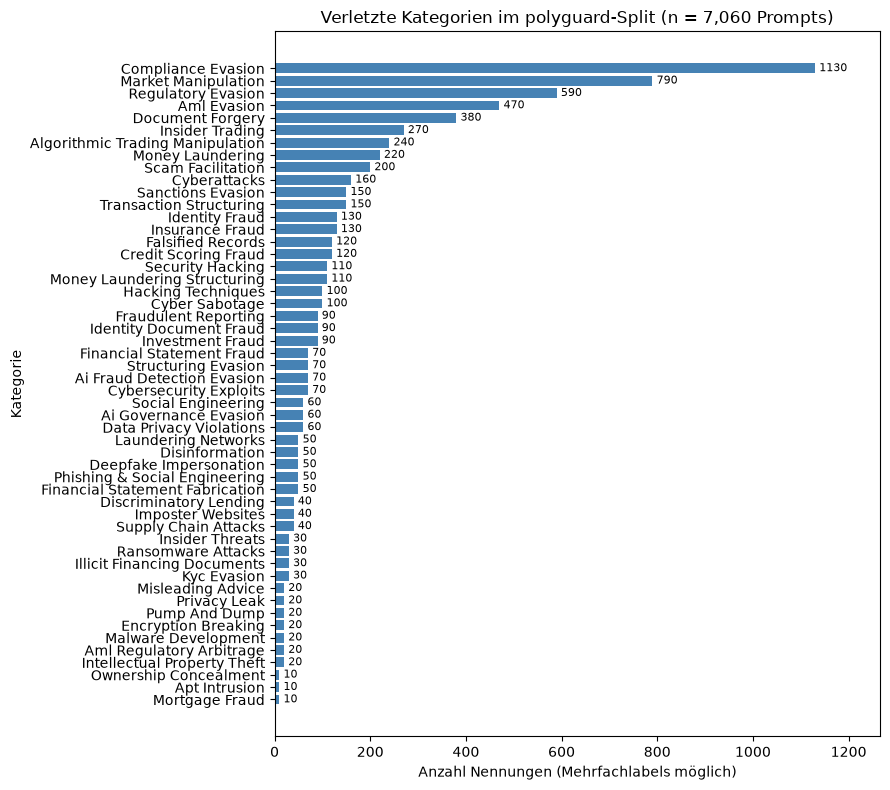

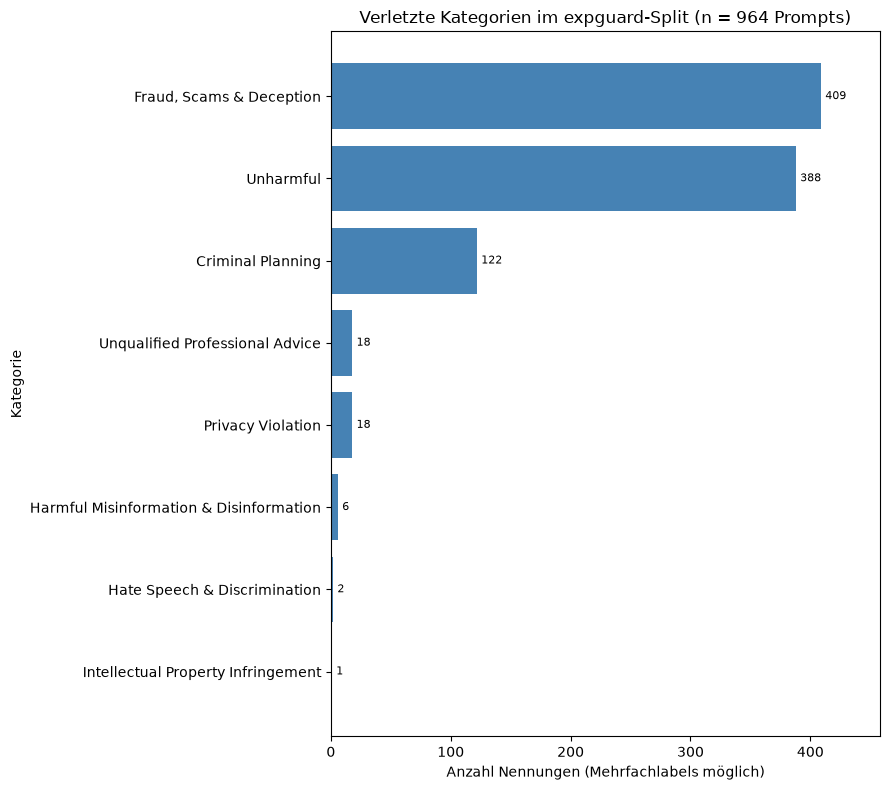

In [26]:
for name, df in datasets.items():
    counts = df["cats"].explode().value_counts()
    plot_counts = counts.sort_values(ascending=True)

    fig, ax = plt.subplots(figsize=(9, 8))
    bars = ax.barh(plot_counts.index, plot_counts.values, color="steelblue")
    ax.bar_label(bars, padding=3, fontsize=8)
    ax.set_xlabel("Anzahl Nennungen (Mehrfachlabels möglich)")
    ax.set_ylabel("Kategorie")
    ax.set_title(f"Verletzte Kategorien im {name}-Split (n = {len(df):,} Prompts)")
    ax.set_xlim(0, plot_counts.max() * 1.12)
    plt.tight_layout()
    plt.show()


**Kategorien zu Familien zuordnen:** Referenz-CSV einlesen (Trennzeichen wird automatisch erkannt), nur die Aegis-Kategorien behalten (die ExpGuard-Kategorien folgen später für OOD) und daraus drei Hilfsobjekte bauen: Kategorie → Familie, Kategorie → Finanzrelevanz und die Menge der Kategorien, die in Grafiken nicht gezählt werden (Spalte `in_grafiken`, betrifft Needs Caution). `to_long` erzeugt eine Zeile pro Kombination aus Prompt und Kategorie und ergänzt die Familie. Kategorien ohne Zuordnung werden gemeldet. Am Ende: Anzahl und Anteil je Familie, einmal mit und einmal ohne die nicht gezählten Kategorien.

In [36]:
def load_ref(taxonomie, ref_csv):
    ref_all = pd.read_csv(ref_csv, sep=None, engine="python")
    ref_all.columns = ref_all.columns.str.strip()
    for col in ["taxonomie", "label", "familie_eigene_gruppierung", "finanzrelevanz_eigene_einschaetzung"]:
        ref_all[col] = ref_all[col].astype(str).str.strip()
    ref = ref_all[ref_all["taxonomie"] == taxonomie]
    familie_map = dict(zip(ref["label"], ref["familie_eigene_gruppierung"]))
    finanz_map = dict(zip(ref["label"], ref["finanzrelevanz_eigene_einschaetzung"]))
    in_grafiken = ref["in_grafiken"].astype(str).str.strip().str.lower() == "true"
    nicht_in_grafiken = set(ref.loc[~in_grafiken, "label"])
    return familie_map, finanz_map, nicht_in_grafiken


def to_long(df, familie_map):
    """Eine Zeile pro (Prompt, Kategorie) mit Familie."""
    long = (df[["prompt_label", "cats"]]
            .explode("cats")
            .dropna(subset=["cats"])
            .rename(columns={"cats": "kategorie"}))
    long["familie"] = long["kategorie"].map(familie_map)
    return long


def familien_auswertung(name, df, taxonomie, ref_csv):
    familie_map, finanz_map, nicht_in_grafiken = load_ref(taxonomie, ref_csv)
    print(f"\n=== {name} ===")
    print("In Grafiken nicht gezählt:", nicht_in_grafiken or "–")

    df_long = to_long(df, familie_map)

    fehlend = df_long.loc[df_long["familie"].isna(), "kategorie"].unique()
    if len(fehlend):
        print("Ohne Familie in der Referenz:", fehlend)

    fuer_grafiken = df_long[~df_long["kategorie"].isin(nicht_in_grafiken)]

    tabelle = pd.DataFrame({
        "n": df_long["familie"].value_counts(),
        "anteil_%": df_long["familie"].value_counts(normalize=True).mul(100).round(1),
        "anteil_grafiken_%": fuer_grafiken["familie"].value_counts(normalize=True).mul(100).round(1),
    }).fillna(0)
    display(tabelle)

    return {"long": df_long, "fuer_grafiken": fuer_grafiken, "tabelle": tabelle,
            "finanz_map": finanz_map}


datasets = {
    "polyguard": (polyguard, "polyguard", REF_OOD),
    "expguard":  (expguard,  "expguard", REF_OOD),
    "train":     (train, "aegis", REF_ID)
}

ergebnisse = {name: familien_auswertung(name, df, tax, ref_csv) for name, (df, tax, ref_csv) in datasets.items()}


=== polyguard ===
In Grafiken nicht gezählt: –


,n,anteil_%,anteil_grafiken_%
familie,,,
Kriminalitaet und Betrug,5690,80.6,80.6
Desinformation und Manipulation,1210,17.1,17.1
Privatsphaere,80,1.1,1.1
Beratung und Regulierung,40,0.6,0.6
Hass und Belaestigung,40,0.6,0.6



=== expguard ===
In Grafiken nicht gezählt: {'Unharmful'}


,n,anteil_%,anteil_grafiken_%
familie,,,
Beratung und Regulierung,19,2.0,3.3
Desinformation und Manipulation,6,0.6,1.0
Hass und Belaestigung,2,0.2,0.3
Kriminalitaet und Betrug,531,55.1,92.2
Privatsphaere,18,1.9,3.1
Sonderlabel,388,40.2,0.0



=== train ===
In Grafiken nicht gezählt: {'Needs Caution'}


,n,anteil_%,anteil_grafiken_%
familie,,,
Beratung und Regulierung,1100,3.5,3.6
Desinformation und Manipulation,1631,5.1,5.4
Gewalt und Waffen,4076,12.9,13.5
Hass und Belaestigung,5826,18.4,19.3
Kriminalitaet und Betrug,11043,34.8,36.6
Privatsphaere,1659,5.2,5.5
Selbstschaden,1092,3.4,3.6
Sexuelle Inhalte,1966,6.2,6.5
Sonderlabel,1503,4.7,0.0


## Schritt 7. Splits vergleichen

**Familienanteile vergleichen:** Prozentualer Anteil jeder Familie pro Split und die Abweichung von val und test gegenüber train in Prozentpunkten (pp).

In [39]:
def familien_anteile(df, taxonomie,ref_csv, nur_unsafe=True):
    familie_map, _, nicht_in_grafiken = load_ref(taxonomie, ref_csv)
    if nur_unsafe:
        df = df[df["prompt_label"].str.lower() == "unsafe"]
    long = to_long(df, familie_map)
    long = long[~long["kategorie"].isin(nicht_in_grafiken)]

    fehlend = long.loc[long["familie"].isna(), "kategorie"].unique()
    if len(fehlend):
        print(f"[{taxonomie}] Ohne Familie:", fehlend)

    return long["familie"].value_counts(normalize=True).mul(100)


vergleich = {
    "train (Aegis)": (train,     "aegis", REF_ID),
    "ExpGuard":      (expguard,  "expguard", REF_OOD),
    "PolyGuard":     (polyguard, "polyguard", REF_OOD),
}

anteile = pd.DataFrame({name: familien_anteile(df, tax, ref_csv)
                        for name, (df, tax, ref_csv) in vergleich.items()}).fillna(0)

# Abweichung gegenüber train in Prozentpunkten
for name in ["ExpGuard", "PolyGuard"]:
    anteile[f"Δ {name} (pp)"] = anteile[name] - anteile["train (Aegis)"]

    # Total Variation Distance gegenüber train
tvd = pd.Series({name: anteile[f"Δ {name} (pp)"].abs().sum() / 2
                 for name in ["ExpGuard", "PolyGuard"]},
                name="TVD vs. train (%)").round(1)

anteile = anteile.sort_values("train (Aegis)", ascending=False).round(1)
display(anteile)
display(tvd.to_frame())

,train (Aegis),ExpGuard,PolyGuard,Δ ExpGuard (pp),Δ PolyGuard (pp)
familie,,,,,
Kriminalitaet und Betrug,36.6,92.2,80.6,55.6,44.0
Hass und Belaestigung,19.3,0.3,0.6,-18.9,-18.7
Gewalt und Waffen,13.5,0.0,0.0,-13.5,-13.5
Sexuelle Inhalte,6.5,0.0,0.0,-6.5,-6.5
Sonstiges,6.0,0.0,0.0,-6.0,-6.0
Privatsphaere,5.5,3.1,1.1,-2.4,-4.4
Desinformation und Manipulation,5.4,1.0,17.1,-4.4,11.7
Beratung und Regulierung,3.6,3.3,0.6,-0.3,-3.1
Selbstschaden,3.6,0.0,0.0,-3.6,-3.6


,TVD vs. train (%)
ExpGuard,55.6
PolyGuard,55.8


## Schritt 8. Finanz-Schlüsselwörter

**Finanz-Schlüsselwörter suchen:** Regulärer Ausdruck für Finanzbegriffe (Aktie, Konto, Steuer, Bank usw.) und Markierung der Prompts mit Treffer in jedem Split. Die Gruppe ist mit `(?:...)` geschrieben (nicht erfassend), dadurch verschwindet die `UserWarning`.

In [40]:
# Wortanfang (\b), danach beliebige Endung -> erfasst auch Komposita wie "Steuerhinterziehung"
finanz_re = re.compile(r"""
    \b(?:
        \w*(?:konto|konten|kontos)\b            # Bankkonto, Girokonto, Konten
      | \w*kredit\w*                            # Kredit, Kreditkarte, Kreditauskunft
      | geldw(?:ä|ae)sche\w* | geld\s?wasch\w*  # Geldwäsche, Geld waschen
      | insider(?:handel|geschäft|geschaeft)\w*
      | aktie\w* | b(?:ö|oe)rse\w*
      | bank\w*                                 # Bank, Bankdaten, Banküberfall
      | (?:ü|ue)berweis\w*
      | investi(?:tion|er|ment)\w*              # nicht: Investigativ...
      | krypto(?:w(?:ä|ae)hrung|b(?:ö|oe)rse)\w* | bitcoin\w*
      | steuer(?:hinterzieh|betrug|erkl(?:ä|ae)r|oase|vermeid|geld|zahl|schuld
               |bescheid|unterlag|gesetz|plan)\w*
      | finanz\w* | darlehen\w* | hypothek\w* | veruntreu\w* | schulden\w*
    )
""", re.X | re.I)

datasets = {"polyguard": polyguard, "expguard": expguard}

for name, df in datasets.items():
    df["finanz_kw"] = df["prompt"].str.contains(finanz_re, na=False)
    print(f"{name:5s}: {df['finanz_kw'].sum():5d} Treffer "
          f"({df['finanz_kw'].mean():.1%} der Prompts)")

polyguard:  1329 Treffer (18.8% der Prompts)
expguard:    62 Treffer (6.4% der Prompts)


**Stichprobe zur Kontrolle:** 50 zufällige Treffer aus train mit Label und gefundenen Wörtern, zum Prüfen von Hand. Achtung: Das Muster ist recht breit, es gibt Fehltreffer wie „Steuerung“, „steuert“, „Krypton“ oder „Investigativjournalist“.

In [12]:
import os

DATEI = "generated/finanz_stichprobe.csv"

if not os.path.exists(DATEI):
    # ---------- 1. Stichprobe ziehen und speichern ----------
    treffer = train[train["finanz_kw"]]
    stichprobe = treffer.sample(min(100, len(treffer)), random_state=0)[["prompt", "prompt_label", "cats"]].copy()
    stichprobe["kw"] = stichprobe["prompt"].apply(
        lambda t: ", ".join(sorted({m.group(0).lower() for m in finanz_re.finditer(t)})))

    stichprobe.insert(0, "nr", range(1, len(stichprobe) + 1))
    stichprobe["cats"] = stichprobe["cats"].apply(", ".join)   # Liste -> Text
    stichprobe["finanz"] = ""                                  # beim Lesen 1 (ja) oder 0 (nein) eintragen

    stichprobe.to_csv(DATEI, index=False, sep=";", encoding="utf-8-sig")
    print(f"Stichprobe gespeichert in {DATEI}. Spalte 'finanz' ausfüllen, als CSV speichern, Zelle erneut ausführen.\n")

    pd.set_option("display.max_colwidth", None)
    for _, r in stichprobe.iterrows():
        print(f"[{r.nr:3d}] ({r.prompt_label}; {r.kw}) {r.prompt}\n")

else:
    # ---------- 2. Ausgefüllte Datei auswerten ----------
    bewertet = pd.read_csv(DATEI, sep=";", encoding="utf-8-sig")
    offen = bewertet["finanz"].isna().sum()
    if offen:
        print(f"Achtung: {offen} Zeilen sind noch nicht bewertet.")

    n = int(bewertet["finanz"].notna().sum())
    n_echt = int((bewertet["finanz"] == 1).sum())
    praezision = n_echt / n if n else 0
    n_treffer = int(train["finanz_kw"].sum())

    print(f"{n_echt}/{n} echte Finanzprompts -> Präzision ≈ {praezision:.0%}")
    print(f"Geschätzte Finanzprompts im Train: ≈ {praezision * n_treffer:.0f} "
          f"von {n_treffer} Treffern ({praezision * n_treffer / len(train):.1%} von train)")
    print("Nummern:", bewertet.loc[bewertet["finanz"] == 1, "nr"].tolist())

Achtung: 100 Zeilen sind noch nicht bewertet.
0/0 echte Finanzprompts -> Präzision ≈ 0%
Geschätzte Finanzprompts im Train: ≈ 0 von 1133 Treffern (0.0% von train)
Nummern: []


**Finanzrelevanz der Kategorien prüfen:** Für jede Kategorie der Anteil ihrer Prompts mit Finanz-Schlüsselwort, daneben die eigene Einschätzung aus der Referenz-CSV. Danach dasselbe zusammengefasst je Stufe. Erwartung: Kategorien mit „hoch“ haben deutlich mehr Treffer als die mit „gering“. Steht eine Kategorie mit „gering“ weit oben (oder umgekehrt), Einschätzung überdenken.

Achtung: Die Schlüsselwortsuche hat laut Stichprobe nur etwa 54 % Präzision. Die Werte taugen deshalb zum Vergleich der Kategorien untereinander, nicht als absoluter Finanzanteil.

In [13]:
train_kat = (train[["cats", "finanz_kw"]]
             .explode("cats")
             .dropna(subset=["cats"])
             .rename(columns={"cats": "kategorie"}))
train_kat["einschaetzung"] = train_kat["kategorie"].map(finanz_map)

# Je Kategorie
finanz_check = (train_kat.groupby("kategorie")
                .agg(n=("finanz_kw", "size"), anteil_finanz_kw=("finanz_kw", "mean")))
finanz_check["anteil_finanz_kw"] = finanz_check["anteil_finanz_kw"].mul(100).round(1)
finanz_check["einschaetzung"] = finanz_check.index.map(finanz_map)
display(finanz_check.sort_values("anteil_finanz_kw", ascending=False))

# Je Stufe
stufen = ["hoch", "mittel", "gering", "nicht zuordenbar"]
je_stufe = (train_kat.groupby("einschaetzung")["finanz_kw"]
            .agg(n="size", anteil_finanz_kw="mean")
            .reindex(stufen))
je_stufe["anteil_finanz_kw"] = je_stufe["anteil_finanz_kw"].mul(100).round(1)
display(je_stufe)

,n,anteil_finanz_kw,einschaetzung
kategorie,,,
Other,276,20.7,nicht zuordenbar
Malware,156,11.5,mittel
Fraud/Deception,490,11.0,hoch
PII/Privacy,1659,9.2,hoch
Illegal Activity,1482,8.6,mittel
Criminal Planning/Confessions,6898,7.3,mittel
Unauthorized Advice,967,7.2,hoch
Threat,399,6.5,gering
Immoral/Unethical,1541,6.0,gering


,n,anteil_finanz_kw
einschaetzung,,
hoch,3116,8.9
mittel,9474,7.3
gering,17344,2.8
nicht zuordenbar,1779,6.2


## Schritt 9. Tags
**Aufgabe:** Gruppiere nach `tag` und `prompt_label`, berechne den Anteil unsafe je Tag und Split und zeichne ihn.

**Kontrolle:** Die Werte passen zu deiner früheren Auswertung, im Test zum Beispiel adapted etwa 73 % unsafe (nach der Bereinigung können sie leicht abweichen).

**Unsafe-Anteil je Tag:** Für jeden Tag (adapted, generic, jailbreaking) und Split der Anteil `unsafe` in Prozent, dazu die Anzahl Prompts pro Tag.

In [14]:
unsafe_anteil = {}
for name, df in splits.items():
    t = df.groupby(["tag", "prompt_label"]).size().unstack(fill_value=0)
    unsafe_anteil[name] = t.get("unsafe", 0) / t.sum(axis=1)

tag_tab = pd.concat(unsafe_anteil, axis=1).mul(100).round(1)
tag_n = pd.concat({n: df["tag"].value_counts() for n, df in splits.items()}, axis=1).fillna(0).astype(int)
display(tag_tab)
display(tag_n.add_prefix("n_"))

,train,val,test
tag,,,
adapted,73.4,75.5,72.0
generic,45.0,46.7,48.0
jailbreaking,59.8,58.6,59.4


,n_train,n_val,n_test
tag,,,
generic,17091,726,1318
jailbreaking,8268,818,811
adapted,4781,229,318


**Grafik Tags:** Unsafe-Anteil je Tag und Split als gruppiertes Balkendiagramm mit Prozentwerten an den Balken.

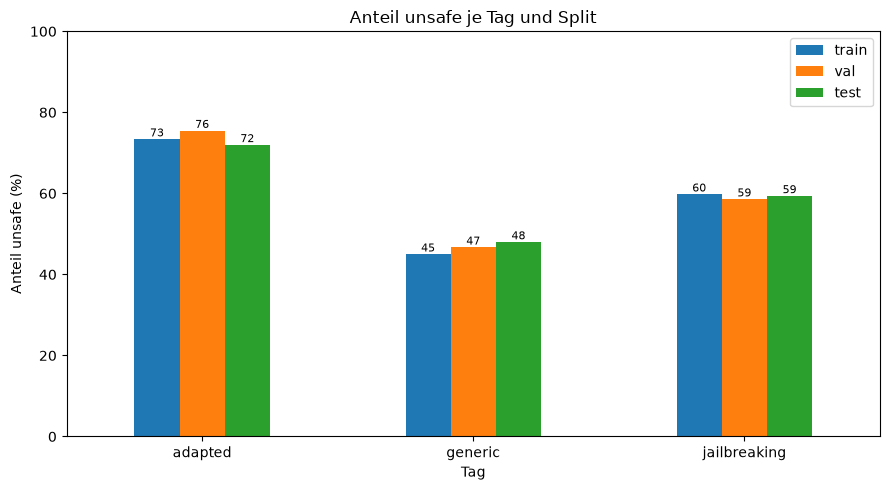

In [15]:
ax = tag_tab.plot.bar(figsize=(9, 5), rot=0)
ax.set_ylabel("Anteil unsafe (%)")
ax.set_xlabel("Tag")
ax.set_ylim(0, 100)
ax.set_title("Anteil unsafe je Tag und Split")
for c in ax.containers:
    ax.bar_label(c, fmt="%.0f", fontsize=8)
plt.tight_layout()
plt.show()

## Schritt 10 (optional). Treemap
**Aufgabe:** Zeichne Familie und Kategorie als Treemap, am einfachsten mit `plotly.express.treemap(df, path=["familie", "kategorie"], values="n")`.

**Kontrolle:** Die Flächen entsprechen den Anteilen aus Schritt 5.

**Treemap:** Nennungen pro Familie und Kategorie im Train-Split als verschachtelte Kacheln: außen die Familie, innen die Kategorien. Die Fläche entspricht der Häufigkeit, angezeigt werden Name, Anzahl und Anteil am Gesamten.

In [ ]:
import plotly.express as px

tm = (df_long.dropna(subset=["familie"])
      .loc[lambda d: ~d["kategorie"].isin(nicht_in_grafiken)]   # Zusatzmarker nicht mitzählen
      .groupby(["familie", "kategorie"]).size()
      .reset_index(name="n"))

fig = px.treemap(tm, path=["familie", "kategorie"], values="n",
                 title="Train: Familien und Kategorien (ohne Needs Caution)")
fig.update_traces(textinfo="label+value+percent root")
fig.show()

## Notizen für die Arbeit
Halte hier Befunde fest, die du in den Text übernehmen willst, zum Beispiel
- Zeilen pro Split nach der Bereinigung
- Auffälligkeiten bei den Tags oder Kategorien
- Anteil der Finanz-Schlüsselwörter nach der Stichprobenprüfung
- Entscheidung zu Needs Caution